In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# This is the standard dataset used in this course
url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/historical_automobile_sales.csv'
df = pd.read_csv(url)

df.head()

,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1/31/1980,1980,Jan,1,108.24,0.50,27483.571,1558,7,60.223,0.010000,5.4,456.0,Supperminicar,Georgia
1,2/29/1980,1980,Feb,1,98.75,0.75,24308.678,3048,4,45.986,-0.309594,4.8,555.9,Supperminicar,New York
2,3/31/1980,1980,Mar,1,107.48,0.20,28238.443,3137,3,35.141,-0.308614,3.4,620.0,Mediumfamilycar,New York
3,4/30/1980,1980,Apr,1,115.01,1.00,32615.149,1653,7,45.673,0.230596,4.2,702.8,Supperminicar,Illinois
4,5/31/1980,1980,May,1,98.72,0.20,23829.233,1319,4,52.997,0.138197,5.3,770.4,Smallfamiliycar,California


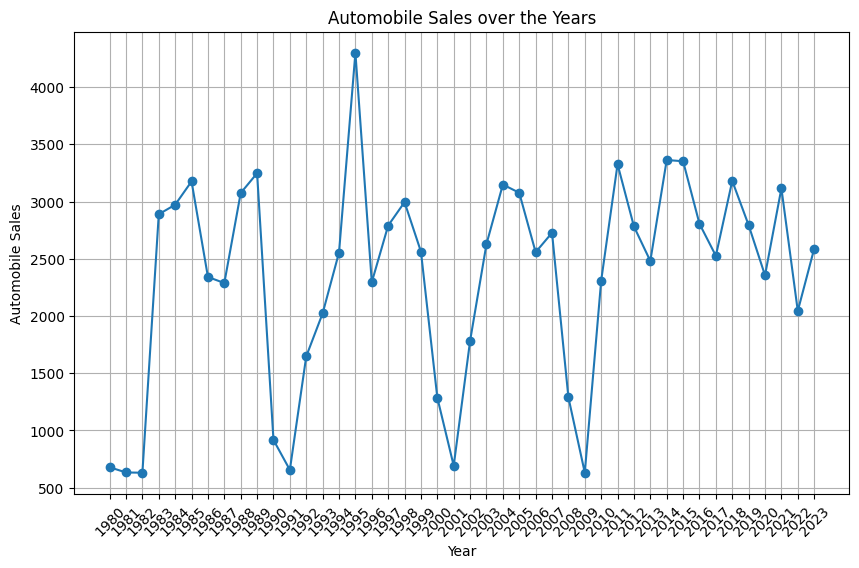

In [4]:
df_line = df.groupby('Year')['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(10, 6))
plt.plot(df_line['Year'], df_line['Automobile_Sales'], marker='o')
plt.title('Automobile Sales over the Years')
plt.xlabel('Year')
plt.ylabel('Automobile Sales')
plt.xticks(df_line['Year'], rotation=45)
plt.grid(True)
plt.show()

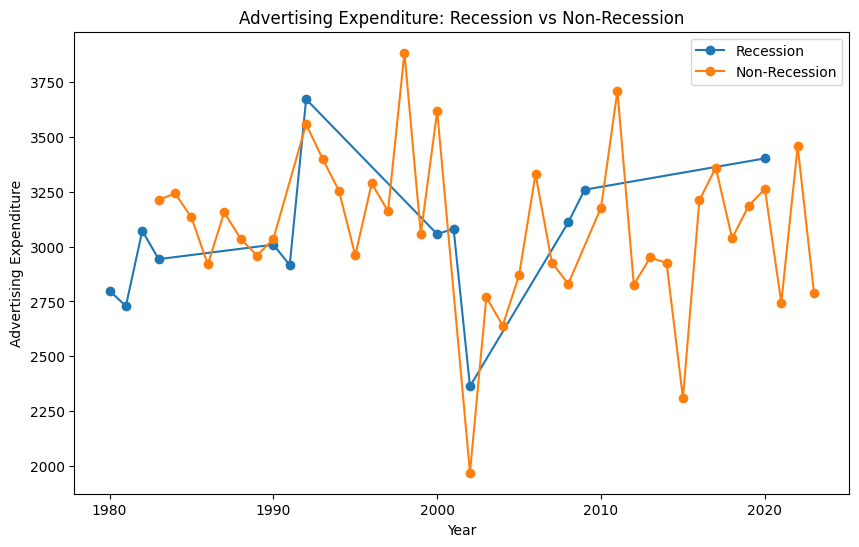

In [5]:
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

df_rec = rec_data.groupby('Year')['Advertising_Expenditure'].mean().reset_index()
df_non_rec = non_rec_data.groupby('Year')['Advertising_Expenditure'].mean().reset_index()

plt.figure(figsize=(10,6))
plt.plot(df_rec['Year'], df_rec['Advertising_Expenditure'], label='Recession', marker='o')
plt.plot(df_non_rec['Year'], df_non_rec['Advertising_Expenditure'], label='Non-Recession', marker='o')
plt.title('Advertising Expenditure: Recession vs Non-Recession')
plt.xlabel('Year')
plt.ylabel('Advertising Expenditure')
plt.legend()
plt.show()

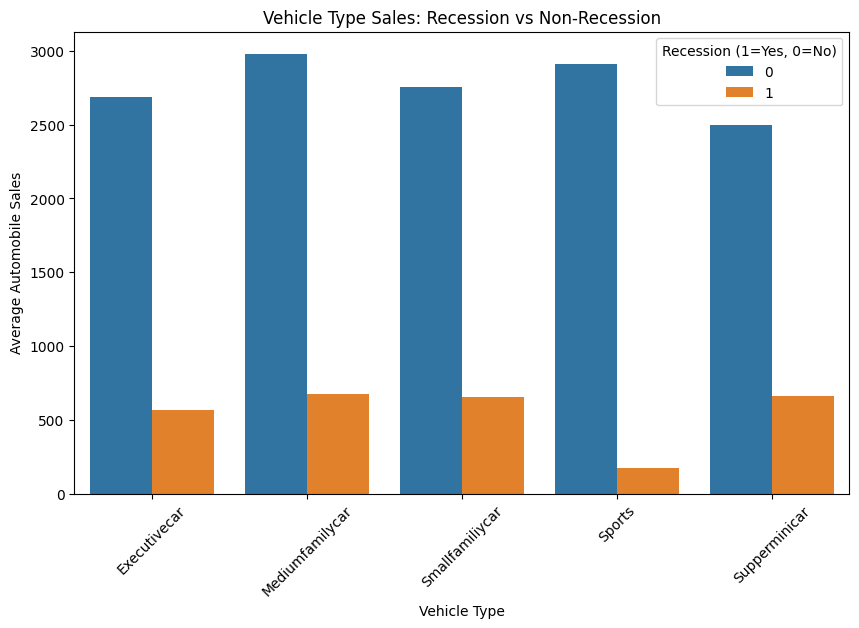

In [6]:
df_bar = df.groupby(['Recession', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(10,6))
sns.barplot(data=df_bar, x='Vehicle_Type', y='Automobile_Sales', hue='Recession')
plt.title('Vehicle Type Sales: Recession vs Non-Recession')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Automobile Sales')
plt.xticks(rotation=45)
plt.legend(title='Recession (1=Yes, 0=No)')
plt.show()

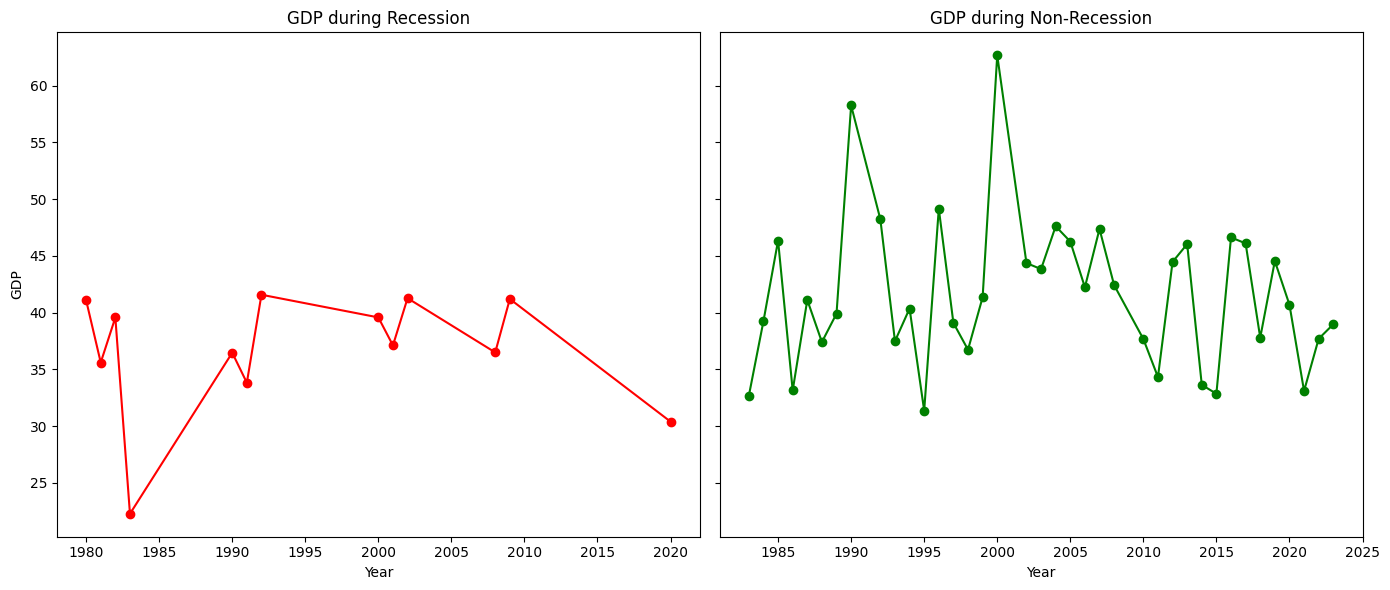

In [7]:
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].plot(rec_data.groupby('Year')['GDP'].mean(), marker='o', color='red')
axes[0].set_title('GDP during Recession')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('GDP')

axes[1].plot(non_rec_data.groupby('Year')['GDP'].mean(), marker='o', color='green')
axes[1].set_title('GDP during Non-Recession')
axes[1].set_xlabel('Year')

plt.tight_layout()
plt.show()

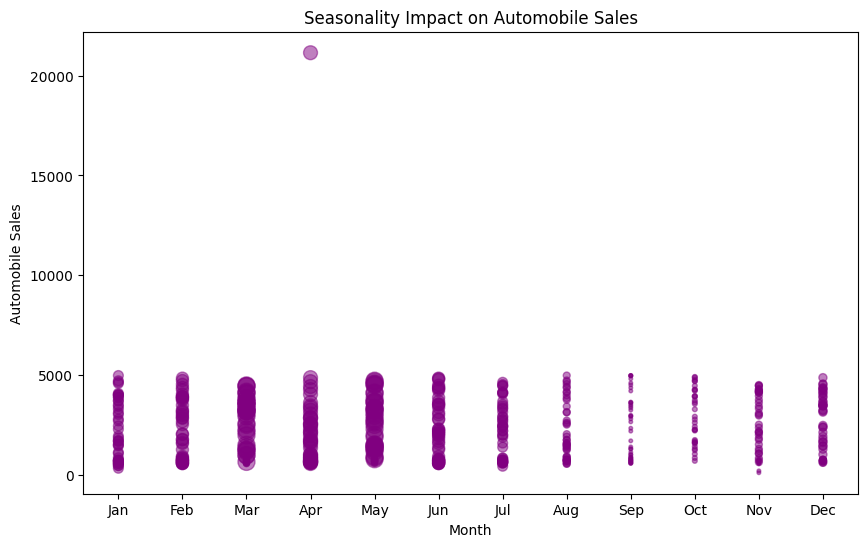

In [8]:
plt.figure(figsize=(10,6))
size = df['Seasonality_Weight'] * 100  # scale for visibility

plt.scatter(df['Month'], df['Automobile_Sales'], s=size, alpha=0.5, c='purple')
plt.title('Seasonality Impact on Automobile Sales')
plt.xlabel('Month')
plt.ylabel('Automobile Sales')
plt.show()

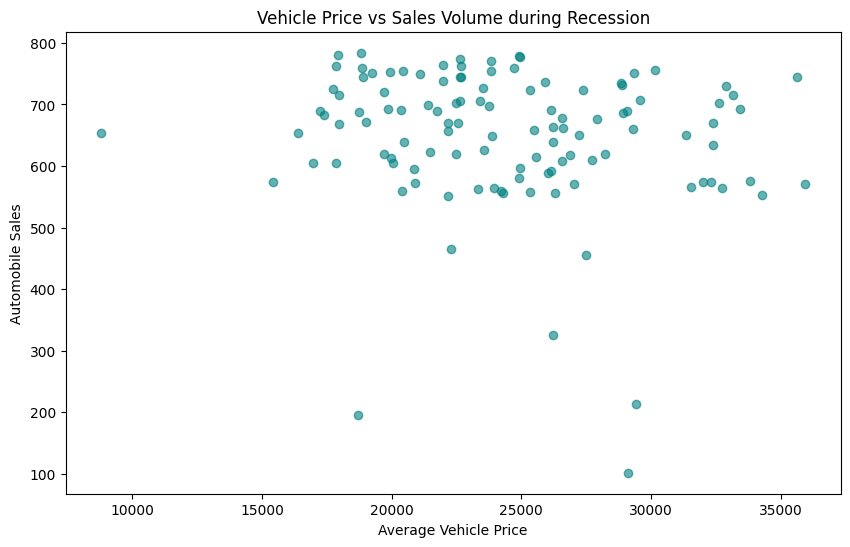

In [9]:
rec_data = df[df['Recession'] == 1]

plt.figure(figsize=(10,6))
plt.scatter(rec_data['Price'], rec_data['Automobile_Sales'], alpha=0.6, color='teal')
plt.title('Vehicle Price vs Sales Volume during Recession')
plt.xlabel('Average Vehicle Price')
plt.ylabel('Automobile Sales')
plt.show()

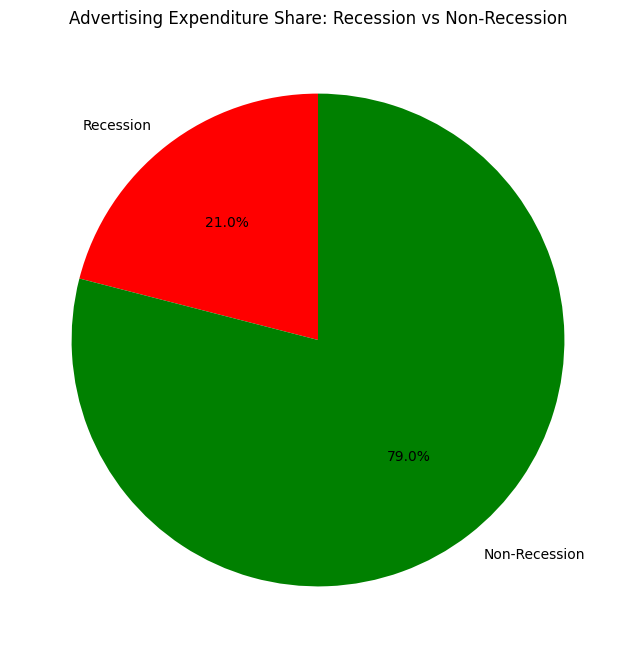

In [10]:
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

total_adv = [rec_data['Advertising_Expenditure'].sum(), non_rec_data['Advertising_Expenditure'].sum()]
labels = ['Recession', 'Non-Recession']

plt.figure(figsize=(8,8))
plt.pie(total_adv, labels=labels, autopct='%1.1f%%', startangle=90, colors=['red','green'])
plt.title('Advertising Expenditure Share: Recession vs Non-Recession')
plt.show()

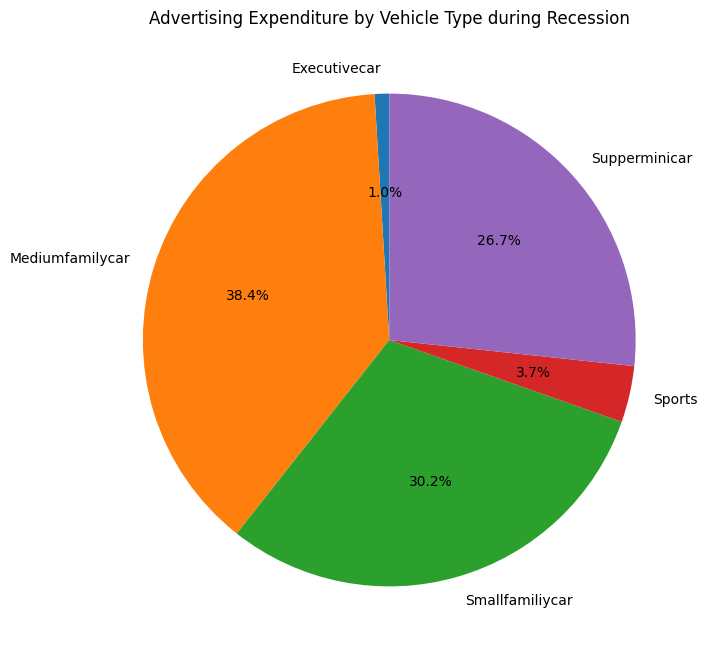

In [11]:
rec_data = df[df['Recession'] == 1]
adv_by_type = rec_data.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

plt.figure(figsize=(8,8))
plt.pie(adv_by_type, labels=adv_by_type.index, autopct='%1.1f%%', startangle=90)
plt.title('Advertising Expenditure by Vehicle Type during Recession')
plt.show()

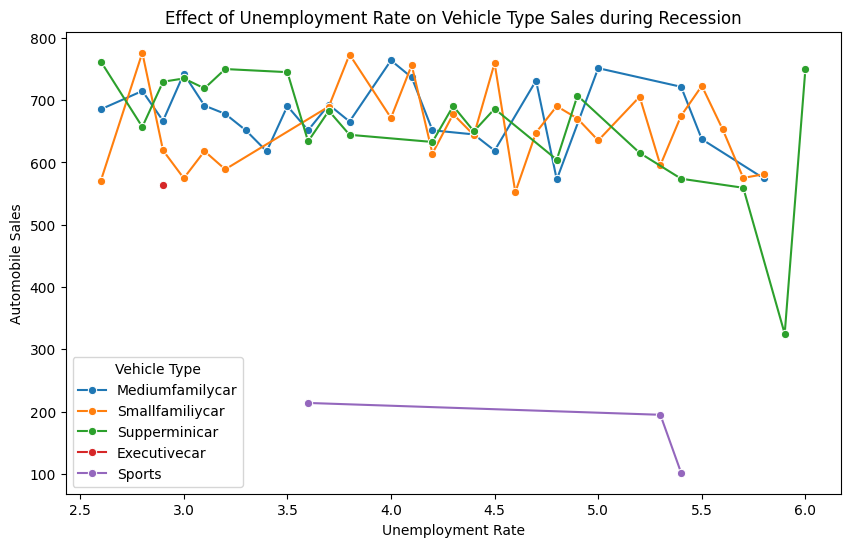

In [12]:
rec_data = df[df['Recession'] == 1]
df_unemp = rec_data.groupby(['unemployment_rate', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(10,6))
sns.lineplot(data=df_unemp, x='unemployment_rate', y='Automobile_Sales', hue='Vehicle_Type', marker='o')
plt.title('Effect of Unemployment Rate on Vehicle Type Sales during Recession')
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.legend(title='Vehicle Type')
plt.show()